# Has Macao's border reopened — or been rebuilt?

**A structural analysis of cross-border movements through Macao's checkpoints, 2018–2025**

Macao is a city of roughly 690,000 residents that recorded 117.9 million inbound border crossings in 2025.
Almost everything the economy depends on — visitors, gaming revenue, retail, and an increasingly mobile
local workforce — passes through a handful of checkpoints. When the COVID-19 border regime closed those
checkpoints in 2020, the whole system was forced to reorganise.

This notebook asks a question that a simple "is tourism back?" headline cannot answer:

> **Did Macao's cross-border system return to its pre-pandemic shape, or did the pandemic permanently
> reallocate traffic between checkpoints and between types of traveller?**

The answer matters for transport planning, retail site selection and tourism marketing, because a
recovered *total* can hide a completely different *structure* underneath it.

---

### Dataset

| | |
|---|---|
| **Source** | Statistics and Census Service (DSEC) of the Macao SAR, via the Macao Government Open Data Platform (`data.gov.mo`) |
| **Datasets** | 各地居民出入境人數 · 各入境事務站出入境人數 · 中國居民出入境人數 (dataset IDs `3546225a-2a34-4645-b01e-6752aed03993`) |
| **Licence** | 完全開放 / Fully open — free to use, reuse and redistribute with attribution |
| **Coverage** | Calendar years 2018–2025, annual totals, persons (not unique individuals) |
| **Unit of analysis** | One *movement* across the boundary. A visitor who enters and leaves counts twice |

Because the data counts movements rather than people, every figure below is a **flow**, not a headcount.
This distinction turns out to be central to the findings.

## 1. Setup

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------- paths
# The notebook lives in notebooks/; the repo root is one level up.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- plot style
INK = "#1f2933"        # primary text
MUTED = "#7b8794"      # secondary text
GRID = "#dfe3e8"
ACCENT = "#c8102e"     # highlight (used sparingly)
SERIES = ["#2f5d8a", "#c8102e", "#d98c2b", "#4a8c6f", "#8b6aa8", "#6b7c8c"]

mpl.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 200,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.titlecolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "legend.frameon": False,
})

def millions(x, _pos=None):
    return f"{x / 1e6:,.0f}M"

def save(fig, name):
    out = FIG / name
    fig.savefig(out, bbox_inches="tight", facecolor="white")
    print(f"saved -> {out.relative_to(ROOT)}")

## 2. Loading the three raw tables

Each table arrived as an Excel workbook inside a single archive from the open-data portal.
The column names carry a leading/trailing space (`'year '`) that has to be stripped before anything else works.

In [2]:
FILES = {
    "by_resident":   "dsec_crossborder_by_resident_2018_2025.xlsx",
    "by_checkpoint": "dsec_crossborder_by_checkpoint_2018_2025.xlsx",
    "mainland":      "dsec_crossborder_mainland_visits_2018_2025.xlsx",
}

raw = {}
for key, fname in FILES.items():
    df = pd.read_excel(RAW / fname)
    df.columns = [c.strip() for c in df.columns]      # 'year ' -> 'year'
    raw[key] = df
    print(f"{key:14s} {df.shape}  {list(df.columns)}")

by_resident    (120, 8)  ['year', 'residentTC', 'residentPT', 'residentEN', 'typeTC', 'typePT', 'typeEN', 'number']
by_checkpoint  (210, 8)  ['year', 'placeTC', 'placePT', 'placeEN', 'typeTC', 'typePT', 'typeEN', 'number']
mainland       (48, 8)  ['year', 'residentTC', 'residentPT', 'residentEN', 'typeTC', 'typePT', 'typeEN', 'number']


## 3. Two data-quality problems worth documenting

Real open data is rarely tidy. Two issues had to be resolved before any aggregation was trustworthy.

**3.1 The schema changes mid-series.** From 2018 to 2021 each table reports one row per
(origin, direction). From 2022 onwards that row disappears and is replaced by two rows split by
gender. A naive `groupby(['year', 'origin'])` therefore silently drops the last four years.
The fix is to aggregate over gender — sum male + female — and keep the aggregate level as the
single grain of analysis.

**3.2 The checkpoints were renamed.** Between 2020 and 2021 every station name gained the suffix
「出入境事務站」, and the Lotus Bridge checkpoint (路氹城) was superseded by the Hengqin Port
Macao Zone (橫琴口岸澳門口岸區) when the new port opened in August 2020. Left unmapped, a
checkpoint timeline would show one series dying and an unrelated one being born, when in fact the
same corridor simply changed name and capacity.

In [3]:
GENDER = re.compile(r"\((?:男|女)\)$")

def split_person(df, name_col):
    # Return a tidy frame at the (year, name, direction) grain, summing over gender.
    out = df.copy()
    out["name"] = out[name_col].str.replace(GENDER, "", regex=True)
    out["gender"] = out[name_col].str.extract(r"\((男|女)\)$")[0]
    out["direction"] = out["typeTC"].map({"入境": "in", "出境": "out"})
    return (out.groupby(["year", "name", "direction"], as_index=False)["number"]
               .sum()
               .rename(columns={"number": "persons"}))

res = split_person(raw["by_resident"], "residentTC")
chk = split_person(raw["by_checkpoint"], "placeTC")
ml  = split_person(raw["mainland"], "residentTC")

print(res["name"].unique())
print(chk["name"].unique())
print(ml["name"].unique())

<StringArray>
['中國台灣居民', '中國居民(內地)', '中國香港居民', '其他', '澳門居民']
Length: 5, dtype: str
<StringArray>
[           '內港碼頭',            '外港碼頭',              '機場',            '氹仔碼頭',
           '港珠澳大橋',         '珠澳跨境工業區',             '路氹城',              '關閘',
   '內港及遊艇碼頭出入境事務站',      '外港碼頭出入境事務站',        '機場出入境事務站', '橫琴口岸澳門口岸區出入境事務站',
      '氹仔碼頭出入境事務站',     '港珠澳大橋出入境事務站',   '珠澳跨境工業區出入境事務站',        '關閘出入境事務站',
        '青茂出入境事務站']
Length: 17, dtype: str
<StringArray>
['中國居民(內地)', '中國居民(內地-個人遊)']
Length: 2, dtype: str


In [4]:
# --- origin labels -------------------------------------------------------
ORIGIN_EN = {
    "中國居民(內地)": "Mainland China",
    "澳門居民": "Macao residents",
    "中國香港居民": "Hong Kong, China",
    "中國台灣居民": "Taiwan, China",
    "其他": "Other countries/regions",
}
res["origin"] = res["name"].map(ORIGIN_EN)

# --- checkpoint harmonisation -------------------------------------------
# old label (2018-2020)  ->  canonical label used for the whole series
CHECKPOINT_EN = {
    "關閘": "Border Gate (Gongbei)",
    "關閘出入境事務站": "Border Gate (Gongbei)",
    "青茂出入境事務站": "Qingmao",
    "路氹城": "Hengqin Port (Macao Zone)",
    "橫琴口岸澳門口岸區出入境事務站": "Hengqin Port (Macao Zone)",
    "港珠澳大橋": "HZMB Port",
    "港珠澳大橋出入境事務站": "HZMB Port",
    "機場": "Airport",
    "機場出入境事務站": "Airport",
    "氹仔碼頭": "Taipa Ferry Terminal",
    "氹仔碼頭出入境事務站": "Taipa Ferry Terminal",
    "外港碼頭": "Outer Harbour Terminal",
    "外港碼頭出入境事務站": "Outer Harbour Terminal",
    "內港碼頭": "Inner Harbour Pier",
    "內港及遊艇碼頭出入境事務站": "Inner Harbour Pier",
    "珠澳跨境工業區": "Cross-border Industrial Park",
    "珠澳跨境工業區出入境事務站": "Cross-border Industrial Park",
}
chk["checkpoint"] = chk["name"].map(CHECKPOINT_EN)
assert chk["checkpoint"].notna().all(), "unmapped checkpoint name"

assert res["origin"].notna().all(), "unmapped origin"
print("unmapped rows:", chk.loc[chk.checkpoint.isna(), "name"].unique())
print(sorted(chk["checkpoint"].unique()))

unmapped rows: <StringArray>
[]
Length: 0, dtype: str
['Airport', 'Border Gate (Gongbei)', 'Cross-border Industrial Park', 'HZMB Port', 'Hengqin Port (Macao Zone)', 'Inner Harbour Pier', 'Outer Harbour Terminal', 'Qingmao', 'Taipa Ferry Terminal']


### 3.3 Validation: do the three tables agree?

The origin table and the checkpoint table describe the *same* population of movements, so their yearly
totals must match to the unit. This is a cheap and strong integrity check — if the checkpoint names
had been mapped incorrectly we would see traffic appear or vanish.

In [5]:
tot_res = res.groupby(["year", "direction"])["persons"].sum().unstack()
tot_chk = chk.groupby(["year", "direction"])["persons"].sum().unstack()

check = pd.DataFrame({
    "by_origin": tot_res["in"],
    "by_checkpoint": tot_chk["in"],
})
check["difference"] = check["by_checkpoint"] - check["by_origin"]
check["match"] = check["difference"].abs() < 1
display(check)

,by_origin,by_checkpoint,difference,match
year,,,,
2018,89733895,89733895,0,True
2019,97395673,97395673,0,True
2020,34732477,34732477,0,True
2021,53011797,53011797,0,True
2022,48977599,48977599,0,True
2023,91458334,91458334,0,True
2024,107434375,107434375,0,True
2025,117944603,117944603,0,True


All eight years reconcile exactly, which means the checkpoint mapping is complete: nothing was
dropped and nothing was double-counted.

### 3.4 A third quality flag, kept visible

One series does *not* pass inspection. The Mainland "individual visit" (個人遊) count for 2021 and 2022
is reported as **2,449,143 in both years** — and the 2022 figure is exactly the sum of its own male and
female components. Two different years producing an identical seven-digit number is almost certainly a
publication artefact rather than a real coincidence. Those two points are marked as unreliable in
Figure 5 rather than being silently deleted.

In [6]:
iv = (ml[ml.direction == "in"]
        .pivot_table(index="year", columns="name", values="persons", aggfunc="sum"))
MAINLAND, IVISIT = "中國居民(內地)", "中國居民(內地-個人遊)"
iv["individual_share_pct"] = iv[IVISIT] / iv[MAINLAND] * 100
display(iv[[MAINLAND, IVISIT, "individual_share_pct"]].round(1))

name,中國居民(內地),中國居民(內地-個人遊),individual_share_pct
year,,,
2018,49762393,12267344,24.7
2019,54497415,13071545,24.0
2020,18923063,1865152,9.9
2021,31173655,2449143,7.9
2022,26973528,2449143,9.1
2023,48195244,10634160,22.1
2024,57382738,12281063,21.4
2025,63312490,15440704,24.4


## 4. The headline: a record total that is not the old total

Inbound movements in 2025 (117.9 M) are **21 % above** the 2019 peak (97.4 M). On its own that looks
like a full recovery and then some. Splitting the flow into Macao residents and everybody else shows
that the two groups did not recover at all in the same way.

In [7]:
flow = (res[res.direction == "in"]
          .pivot_table(index="year", columns="origin", values="persons", aggfunc="sum"))
flow["Total"] = flow.sum(axis=1)
flow = flow[["Total", "Macao residents", "Mainland China",
             "Hong Kong, China", "Taiwan, China", "Other countries/regions"]]
display(flow)

visitors = flow["Total"] - flow["Macao residents"]
print(f"2025 vs 2019, all inbound movements : {flow.loc[2025,'Total']/flow.loc[2019,'Total']-1:+.1%}")
print(f"2025 vs 2019, Macao residents       : {flow.loc[2025,'Macao residents']/flow.loc[2019,'Macao residents']-1:+.1%}")
print(f"2025 vs 2019, non-resident visitors : {visitors.loc[2025]/visitors.loc[2019]-1:+.1%}")

origin,Total,Macao residents,Mainland China,"Hong Kong, China","Taiwan, China",Other countries/regions
year,,,,,,
2018,89733895,28445201,49762393,6842002,1121330,3562969
2019,97395673,30421510,54497415,7854539,1125149,3497060
2020,34732477,14425548,18923063,1010351,122099,251416
2021,53011797,20865884,31173655,848544,103143,20571
2022,48977599,21159008,26973528,713547,90956,40560
2023,91458334,33549251,48195244,7497419,545117,1671303
2024,107434375,38971971,57382738,7460281,878899,2740486
2025,117944603,42881611,63312490,7572619,1039196,3138687


2025 vs 2019, all inbound movements : +21.1%
2025 vs 2019, Macao residents       : +41.0%
2025 vs 2019, non-resident visitors : +12.1%


saved -> figures\fig1_flow_overview.png


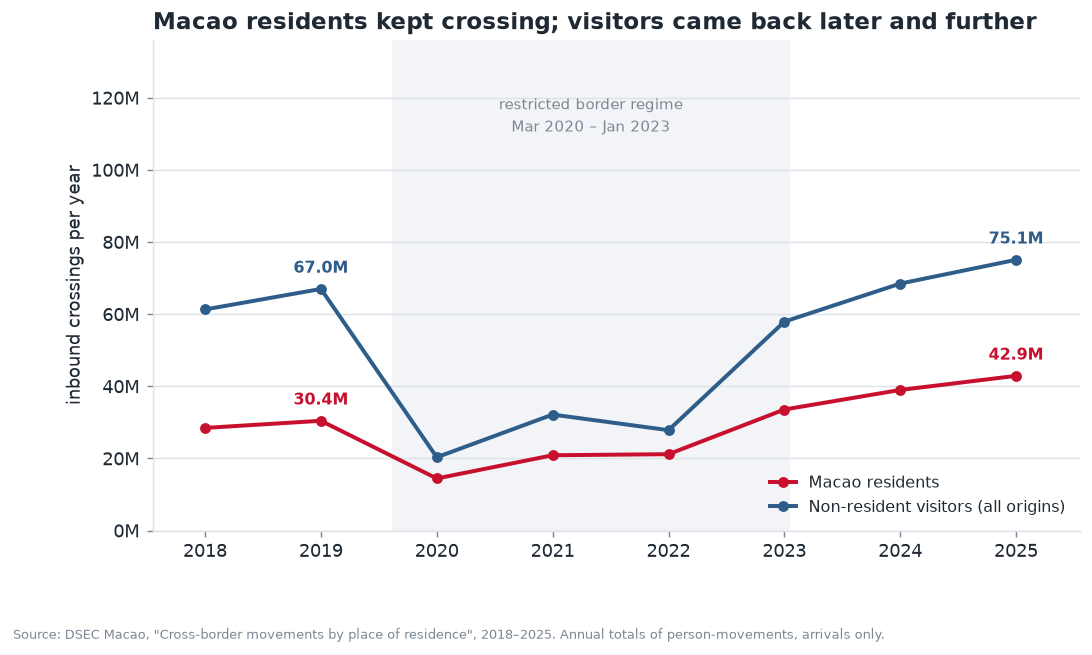

In [8]:
fig, ax = plt.subplots(figsize=(9.2, 4.9))
yrs = flow.index.to_numpy()

# pandemic shading: border restrictions 2020-03 to 2023-01
ax.axvspan(2019.62, 2023.04, color="#f2f4f7", zorder=0)
ax.text(2021.33, 121e6, "restricted border regime\nMar 2020 – Jan 2023",
        ha="center", va="top", fontsize=8.5, color=MUTED, linespacing=1.45)

ax.plot(yrs, flow["Macao residents"], marker="o", ms=5, lw=2.2,
        color=SERIES[1], zorder=3, label="Macao residents")
ax.plot(yrs, visitors, marker="o", ms=5, lw=2.2,
        color=SERIES[0], zorder=3, label="Non-resident visitors (all origins)")

for series, colour in ((flow["Macao residents"], SERIES[1]),
                       (visitors, SERIES[0])):
    for yr in (2019, 2025):
        ax.annotate(f"{series.loc[yr]/1e6:.1f}M", (yr, series.loc[yr]),
                    textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8.8, fontweight="bold", color=colour)

ax.set_xlim(2017.55, 2025.55)
ax.set_ylim(0, 1.36e8)
ax.set_xticks(yrs)
ax.set_yticks(np.arange(0, 1.4e8, 2e7))
ax.yaxis.set_major_formatter(FuncFormatter(millions))
ax.set_ylabel("inbound crossings per year")
ax.set_title("Macao residents kept crossing; visitors came back later and further", loc="left")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="lower right", ncol=1, fontsize=9, handlelength=1.6)

fig.text(0.008, -0.06,
         "Source: DSEC Macao, \"Cross-border movements by place of residence\", 2018–2025. Annual totals of person-movements, arrivals only.",
         fontsize=7.4, color=MUTED)
save(fig, "fig1_flow_overview.png")
plt.show()

**Reading Figure 1.** Resident travel never really collapsed in the same way visitor travel did: from
2020 to 2022 Macao residents still crossed the boundary 14–21 million times a year, and by 2025 they
were 41 % above their 2019 level. Non-resident visitor movements fell to 20.3 M in 2020 (−70 %) and
took until 2024 to pass the 2019 level. The record 2025 total is therefore produced by **local
mobility growing faster than tourism**, not by tourism alone.

## 5. Composition: who is actually crossing?

Figure 2 converts the same numbers into shares. The aggregate "recovery" hides a real change in the mix.

In [9]:
share = flow.drop(columns="Total").div(flow["Total"], axis=0) * 100
order = ["Macao residents", "Mainland China", "Hong Kong, China",
         "Taiwan, China", "Other countries/regions"]
share = share[order]
display(share.round(1))

origin,Macao residents,Mainland China,"Hong Kong, China","Taiwan, China",Other countries/regions
year,,,,,
2018,31.7,55.5,7.6,1.2,4.0
2019,31.2,56.0,8.1,1.2,3.6
2020,41.5,54.5,2.9,0.4,0.7
2021,39.4,58.8,1.6,0.2,0.0
2022,43.2,55.1,1.5,0.2,0.1
2023,36.7,52.7,8.2,0.6,1.8
2024,36.3,53.4,6.9,0.8,2.6
2025,36.4,53.7,6.4,0.9,2.7


saved -> figures\fig2_origin_mix.png


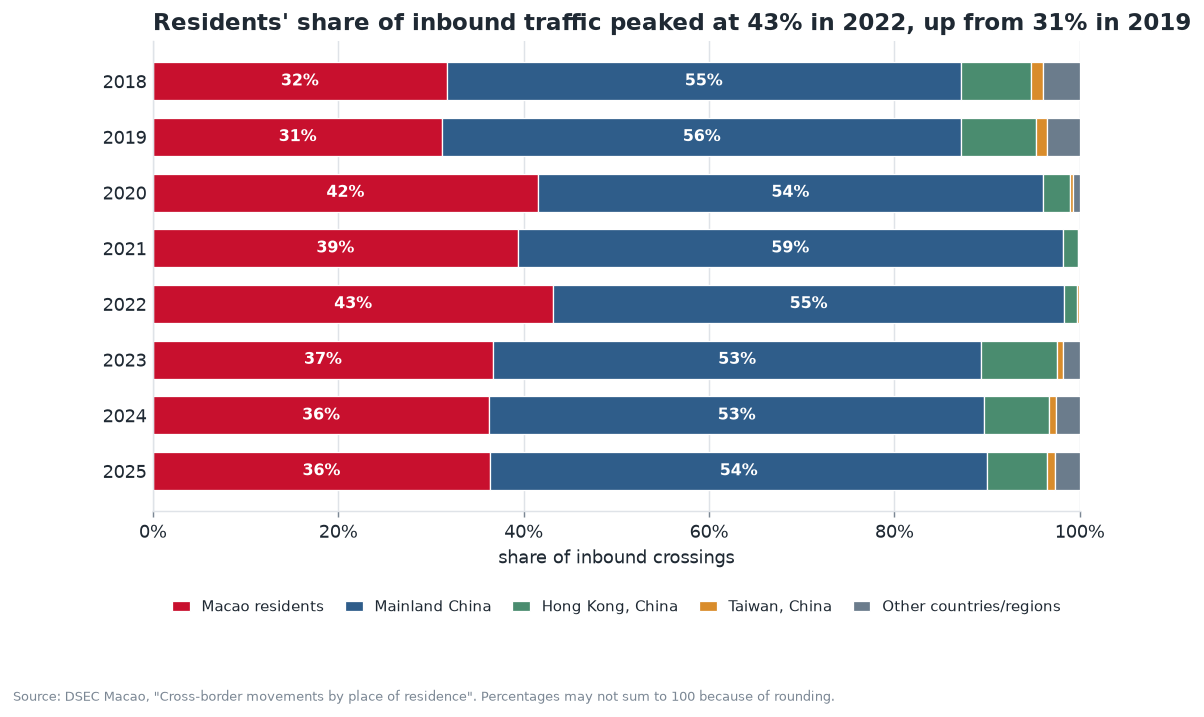

In [10]:
fig, ax = plt.subplots(figsize=(9.2, 4.7))
left = np.zeros(len(share))
pos = np.arange(len(share))
colors = [SERIES[1], SERIES[0], SERIES[3], SERIES[2], SERIES[5]]

for col, colour in zip(order, colors):
    ax.barh(pos, share[col], left=left, color=colour,
            height=0.68, label=col, edgecolor="white", linewidth=0.7)
    left += share[col].to_numpy()

# direct labels for the two segments that matter most
for i, yr in enumerate(share.index):
    ax.text(share.loc[yr, "Macao residents"] / 2, i,
            f"{share.loc[yr,'Macao residents']:.0f}%", ha="center", va="center",
            fontsize=9, color="white", fontweight="bold")
    mid = share.loc[yr, "Macao residents"] + share.loc[yr, "Mainland China"] / 2
    ax.text(mid, i, f"{share.loc[yr,'Mainland China']:.0f}%", ha="center", va="center",
            fontsize=9, color="white", fontweight="bold")

ax.set_yticks(pos)
ax.set_yticklabels(share.index)

ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("share of inbound crossings")
ax.set_ylabel("")
ax.set_title("Residents' share of inbound traffic peaked at 43% in 2022, up from 31% in 2019",
             loc="left")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=5, fontsize=8.2,
          handlelength=1.2, columnspacing=1.4)
ax.tick_params(axis="y", length=0)

fig.text(0.008, -0.20,
         "Source: DSEC Macao, \"Cross-border movements by place of residence\". Percentages may not sum to 100 because of rounding.",
         fontsize=7.4, color=MUTED)
save(fig, "fig2_origin_mix.png")
plt.show()

**Reading Figure 2.** Before the pandemic, roughly two-thirds of every inbound movement was a visitor.
During the closed period that ratio flipped towards residents, peaking at **43.2 % in 2022**, when
Macao residents were almost the only people still able to cross freely. By 2025 the mix has settled at
**36.4 % residents** — four to five points *above* 2019. The border is busier than before, but a larger
share of the traffic is local.

The long-run direction of the tourist flow also changed. Measured against *visitor* arrivals only,
Mainland China's share rose from **81.4 % (2019) to 84.3 % (2025)**, while Hong Kong's fell from
**11.7 % to 10.1 %** — a consolidation onto a single source market that also explains why the land
checkpoints, rather than the airport and ferry terminals, carried the recovery.

## 6. Where did the traffic go? The checkpoint map was redrawn

This is the part a total-level view cannot show. Macao's crossings are concentrated in a few
infrastructure assets, and their relative importance changed dramatically between 2019 and 2025.

In [11]:
cp = (chk[chk.direction == "in"]
        .pivot_table(index="year", columns="checkpoint", values="persons", aggfunc="sum")
        .fillna(0))

focus = ["Border Gate (Gongbei)", "Qingmao", "Hengqin Port (Macao Zone)", "HZMB Port",
         "Airport", "Taipa Ferry Terminal", "Outer Harbour Terminal",
         "Inner Harbour Pier", "Cross-border Industrial Park"]
cp = cp[focus]

tab = pd.DataFrame({
    "2019 (M)": cp.loc[2019] / 1e6,
    "2025 (M)": cp.loc[2025] / 1e6,
    "share 2019 %": cp.loc[2019] / cp.loc[2019].sum() * 100,
    "share 2025 %": cp.loc[2025] / cp.loc[2025].sum() * 100,
})
tab["Δ share pp"] = tab["share 2025 %"] - tab["share 2019 %"]
display(tab.round(1).sort_values("share 2025 %", ascending=False))

,2019 (M),2025 (M),share 2019 %,share 2025 %,Δ share pp
checkpoint,,,,,
Border Gate (Gongbei),72.5,62.2,74.4,52.7,-21.7
Qingmao,0.0,17.6,0.0,14.9,14.9
Hengqin Port (Macao Zone),4.9,15.2,5.0,12.9,7.9
HZMB Port,6.8,14.3,7.0,12.1,5.2
Airport,4.6,3.7,4.7,3.1,-1.6
Taipa Ferry Terminal,3.0,2.4,3.0,2.1,-1.0
Outer Harbour Terminal,4.4,1.6,4.5,1.3,-3.1
Inner Harbour Pier,0.0,0.8,0.0,0.7,0.7
Cross-border Industrial Park,1.3,0.2,1.3,0.2,-1.2


saved -> figures\fig3_checkpoint_share.png


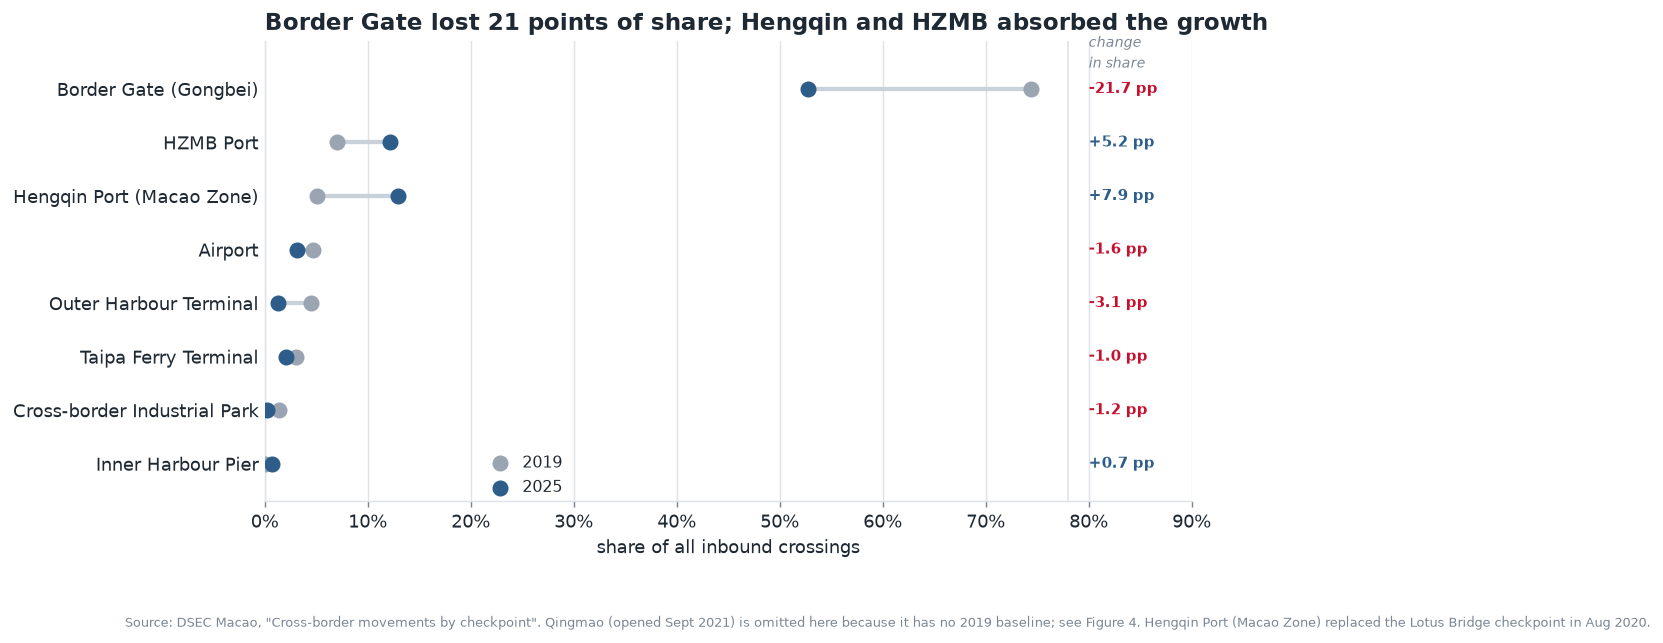

In [12]:
fig, ax = plt.subplots(figsize=(9.2, 4.6))
rows = tab.drop(index="Qingmao").sort_values("share 2019 %")
y = np.arange(len(rows))

ax.hlines(y, rows["share 2019 %"], rows["share 2025 %"], color="#c9d1da", lw=2.4, zorder=1)
ax.scatter(rows["share 2019 %"], y, s=62, color="#9aa5b1", zorder=3, label="2019")
ax.scatter(rows["share 2025 %"], y, s=62, color=SERIES[0], zorder=3, label="2025")

# the change column sits in its own gutter so it can never collide with a bar
ax.axvline(78.0, color=GRID, lw=0.9, zorder=0)
ax.text(80.0, len(rows) - 0.32, "change\nin share", va="center", ha="left",
        fontsize=7.9, color=MUTED, style="italic", linespacing=1.35)
for yi, (idx, r) in enumerate(rows.iterrows()):
    d = r["Δ share pp"]
    ax.text(80.0, yi, f"{d:+.1f} pp", va="center", ha="left", fontsize=8.5,
            color=SERIES[1] if d < 0 else SERIES[0], fontweight="bold")

ax.set_yticks(y)
ax.set_yticklabels(rows.index)
ax.set_xlim(0, 90)
ax.set_ylim(-0.7, len(rows) - 0.1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_xlabel("share of all inbound crossings")
ax.set_title("Border Gate lost 21 points of share; Hengqin and HZMB absorbed the growth", loc="left")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="lower left", bbox_to_anchor=(0.22, -0.02), fontsize=9, handletextpad=0.4)
ax.tick_params(axis="y", length=0)

fig.text(0.008, -0.10,
         "Source: DSEC Macao, \"Cross-border movements by checkpoint\". Qingmao (opened Sept 2021) is omitted here "
         "because it has no 2019 baseline; see Figure 4. Hengqin Port (Macao Zone) replaced the Lotus Bridge checkpoint in Aug 2020.",
         fontsize=7.4, color=MUTED)
save(fig, "fig3_checkpoint_share.png")
plt.show()

**Reading Figure 3.** Border Gate (Gongbei) went from carrying **74.4 %** of all inbound crossings in
2019 to **52.7 %** in 2025 — a loss of 21.7 percentage points — even though its absolute volume only
fell 14 %. The system moved from a single dominant gateway to four substantial ones. Qingmao, which
did not exist before September 2021, is now the second busiest crossing in Macao.

Figure 4 puts the same change in absolute terms, which is where the scale of the reallocation shows.

saved -> figures\fig4_checkpoint_change.png


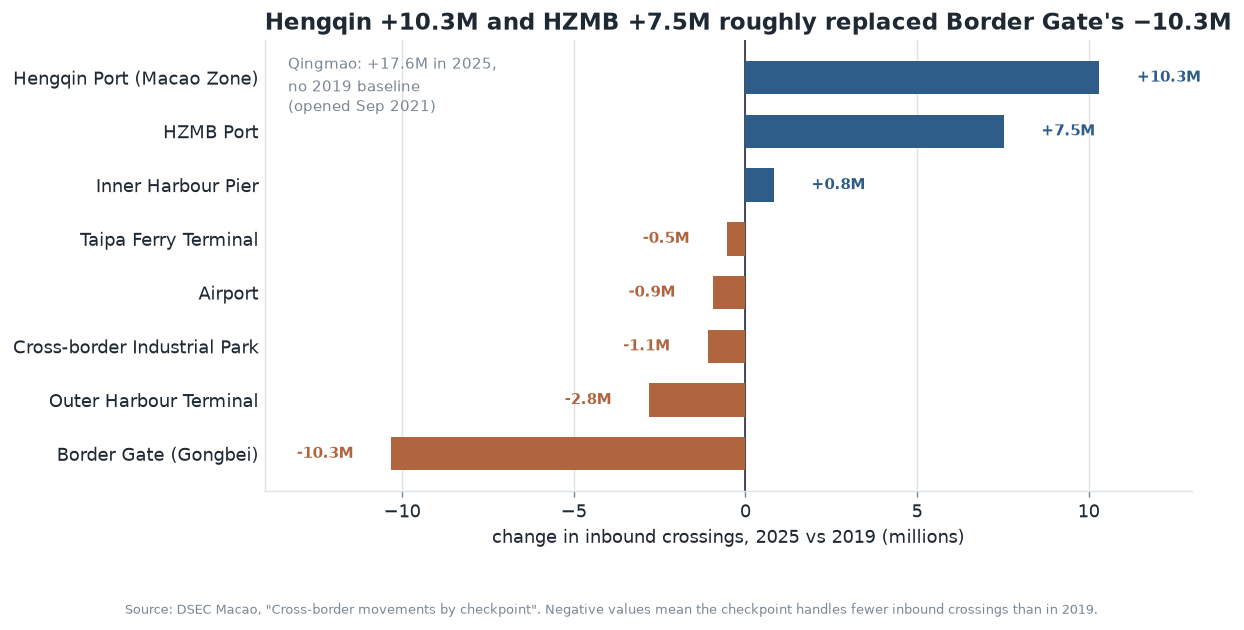

In [13]:
delta = pd.DataFrame({
    "2019": cp.loc[2019],
    "2025": cp.loc[2025],
})
delta["change"] = delta["2025"] - delta["2019"]
delta = delta.drop(index="Qingmao").sort_values("change")

fig, ax = plt.subplots(figsize=(9.2, 4.5))
LOSS = "#b0653f"
colours = [LOSS if v < 0 else SERIES[0] for v in delta["change"]]
y = np.arange(len(delta))
ax.barh(y, delta["change"] / 1e6, color=colours, height=0.62, zorder=2)

for yi, (idx, r) in enumerate(delta.iterrows()):
    v = r["change"] / 1e6
    ax.text(v + (1.1 if v >= 0 else -1.1), yi, f"{v:+.1f}M",
            va="center", ha="left" if v >= 0 else "right",
            fontsize=8.5, fontweight="bold",
            color=LOSS if v < 0 else SERIES[0])

ax.axvline(0, color=INK, lw=0.9, zorder=1)
ax.set_yticks(y)
ax.set_yticklabels(delta.index)
ax.set_xlim(-14, 13)
ax.set_xlabel("change in inbound crossings, 2025 vs 2019 (millions)")
ax.set_title("Hengqin +10.3M and HZMB +7.5M roughly replaced Border Gate's −10.3M", loc="left")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

ax.annotate("Qingmao: +17.6M in 2025,\nno 2019 baseline\n(opened Sep 2021)",
            xy=(0.025, 0.97), xycoords="axes fraction",
            ha="left", va="top", fontsize=8.4, color=MUTED, linespacing=1.4)

fig.text(0.008, -0.10,
         "Source: DSEC Macao, \"Cross-border movements by checkpoint\". Negative values mean the checkpoint "
         "handles fewer inbound crossings than in 2019.",
         fontsize=7.4, color=MUTED)
save(fig, "fig4_checkpoint_change.png")
plt.show()

**Reading Figure 4.** Three land corridors did the work:

* **Hengqin Port (Macao Zone) +10.3 M** — the new port plus the Hengqin development zone, serving the
  growing number of residents who live, work or shop on the Zhuhai side.
* **HZMB Port +7.5 M** — the Hong Kong–Zhuhai–Macao Bridge, whose 2019 volumes were still ramping up
  when the pandemic hit.
* **Qingmao +17.6 M from nothing** — now the second gateway, and physically adjacent to Border Gate.

Against that, Border Gate **−10.3 M** and the two ferry terminals **−2.8 M and −0.5 M**. Sea access has
not recovered: Outer Harbour Terminal is at 36 % of its 2019 volume and Taipa at 82 %. The airport is
still 20 % below 2019, and every air and sea gateway remains under its pre-pandemic level — only the
land crossings grew, which is consistent with Macao's tourist mix having shifted towards arrivals from
the Mainland.

## 7. The Mainland market: tourists, or day-trippers?

If more of the traffic is land-based and Mainland-based, the natural question is whether the *kind* of
Mainland visitor changed. DSEC distinguishes group-tour visitors from individual-visit (個人遊) travellers.

saved -> figures\fig5_individual_visits.png


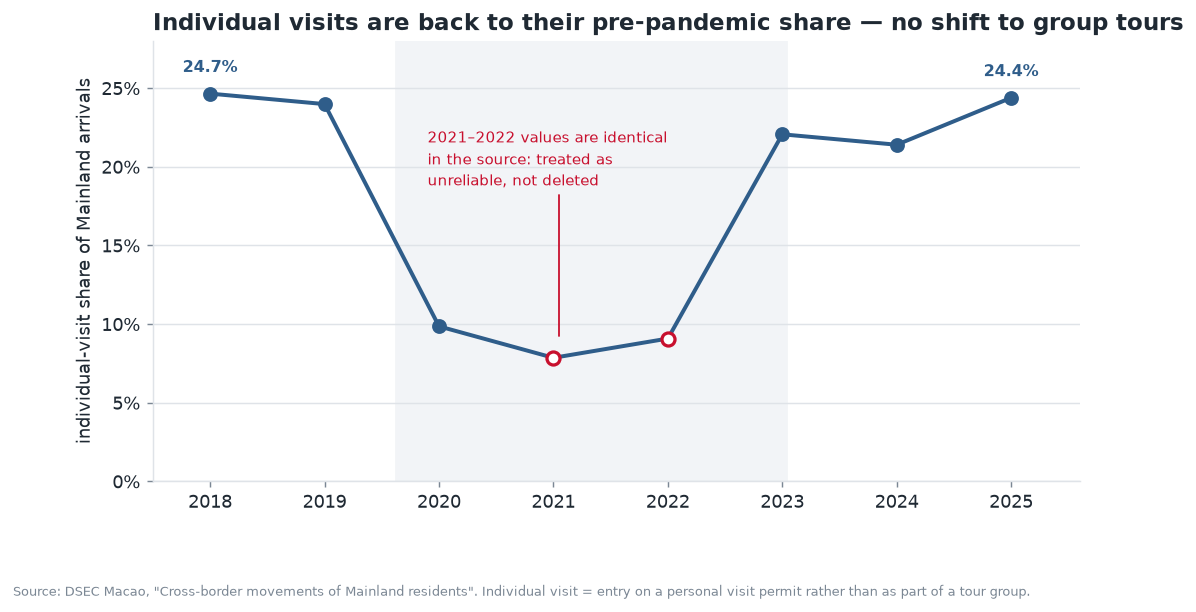

In [14]:
fig, ax = plt.subplots(figsize=(9.2, 4.4))
yrs = iv.index.to_numpy()
flag = [2021, 2022]

ax.plot(yrs, iv["individual_share_pct"], color=SERIES[0], lw=2.2, zorder=2)
ax.scatter([y for y in yrs if y not in flag], iv.loc[[y for y in yrs if y not in flag], "individual_share_pct"],
           s=52, color=SERIES[0], zorder=3)
ax.scatter(flag, iv.loc[flag, "individual_share_pct"], s=52, facecolor="white",
           edgecolor=SERIES[1], linewidth=1.8, zorder=4)
ax.axvspan(2019.62, 2023.04, color="#f2f4f7", zorder=0)

for yr in (2018, 2025):
    ax.annotate(f"{iv.loc[yr,'individual_share_pct']:.1f}%",
                (yr, iv.loc[yr, "individual_share_pct"]),
                textcoords="offset points", xytext=(0, 12), ha="center",
                fontsize=9, fontweight="bold", color=SERIES[0])

ax.annotate("2021–2022 values are identical\nin the source: treated as\nunreliable, not deleted",
            xy=(2021.05, 8.7), xytext=(2019.9, 22.6), fontsize=8.4, color=SERIES[1],
            linespacing=1.45, ha="left", va="top",
            arrowprops=dict(arrowstyle="-", color=SERIES[1], lw=1, shrinkA=0, shrinkB=5,
                            connectionstyle="angle,angleA=0,angleB=90,rad=0"))

ax.set_xlim(2017.5, 2025.6)
ax.set_ylim(0, 28)
ax.set_xticks(yrs)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.set_ylabel("individual-visit share of Mainland arrivals")
ax.set_title("Individual visits are back to their pre-pandemic share — no shift to group tours",
             loc="left")
ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_axisbelow(True)

fig.text(0.008, -0.09,
         "Source: DSEC Macao, \"Cross-border movements of Mainland residents\". Individual visit = entry on a "
         "personal visit permit rather than as part of a tour group.",
         fontsize=7.4, color=MUTED)
save(fig, "fig5_individual_visits.png")
plt.show()

**Reading Figure 5.** Individual-visit travellers made up 24.7 % of Mainland arrivals in 2018 and
24.4 % in 2025 — statistically the same share. The pandemic did not push Macao towards packaged group
tours; it interrupted both and let them resume in the same proportion. This is a useful negative result:
the *composition* of the Mainland market proved more stable than its volume.

---

## 8. Findings

1. **The total is a record; the structure is not the old one.** Inbound crossings reached 117.9 M in 2025,
   +21 % on 2019 — but only because local mobility grew faster than tourism.
2. **Residents, not tourists, drive the new peak.** Macao residents' inbound movements rose 41 % against
   2019, and their share of inbound traffic settled 4–5 points above the pre-pandemic level.
3. **One gateway became four.** Border Gate fell from 74.4 % to 52.7 % of inbound crossings while
   Hengqin Port (+10.3 M), HZMB Port (+7.5 M) and the new Qingmao crossing (+17.6 M) took the difference.
4. **Sea gateways have not recovered.** Outer Harbour Terminal is at 36 % of 2019 volume; the airport
   is at 80 %. The recovery is land-based.
5. **The Mainland market resumed its former shape.** Individual visits are back to ~24 % of Mainland
   arrivals, i.e. the mix was resilient even though the volume was not.

### Limitation

The data counts **movements, not people**, and it is annual. A resident who commutes daily contributes
hundreds of "crossings" while a three-night tourist contributes two, so the growth in the resident share
cannot be converted into a statement about how many people crossed how often. Because there is no
monthly breakdown and no purpose-of-travel field, this analysis can show *that* traffic was reallocated
between checkpoints, but cannot attribute the reallocation to commuting, shopping or tourism with
confidence. A monthly series or an origin–checkpoint cross-tabulation would be needed for that.

## 9. Export the cleaned tables

The two processed files below are what a downstream dashboard or report should consume — they are at a
stable (year, dimension, direction) grain and use English labels.

In [15]:
res.to_csv(PROC / "arrivals_by_origin.csv", index=False, encoding="utf-8-sig")
chk.to_csv(PROC / "arrivals_by_checkpoint.csv", index=False, encoding="utf-8-sig")
print("rows written:", len(res), len(chk))
print(sorted(p.name for p in PROC.iterdir()))

rows written: 80 138
['arrivals_by_checkpoint.csv', 'arrivals_by_origin.csv']
